In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [ ]:
def kmeans(X, k, max_iterations=100):

    # Select k random points as initial centroids
    random_indices = np.random.choice(len(X), k, replace=False)
    centroids = X[random_indices].copy()

    for iteration in range(max_iterations):

        # Calculate distance of every point from every centroid
        distances = np.zeros((len(X), k))

        for i in range(len(X)):
            for j in range(k):
                distances[i, j] = np.sqrt(
                    np.sum((X[i] - centroids[j]) ** 2)
                )

        # Assign each point to nearest centroid
        clusters = np.argmin(distances, axis=1)

        # Calculate new centroids
        new_centroids = np.zeros_like(centroids)

        for j in range(k):

            points = X[clusters == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(points, axis=0)
            else:
                new_centroids[j] = centroids[j]

        # Check if centroids have stopped changing
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return clusters, centroids

In [ ]:
def plot_clusters(X, clusters, centroids, title):

    plt.figure(figsize=(7, 5))

    for cluster in np.unique(clusters):
        points = X[clusters == cluster]
        plt.scatter(
            points[:, 0],
            points[:, 1],
            label="Cluster " + str(cluster)
        )

    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker="X",
        s=200,
        label="Centroids"
    )

    plt.title(title)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend()
    plt.show()

In [ ]:
np.random.seed(42)

cluster1 = np.random.randn(50, 2) + [2, 2]
cluster2 = np.random.randn(50, 2) + [8, 2]
cluster3 = np.random.randn(50, 2) + [5, 7]

X = np.vstack((cluster1, cluster2, cluster3))

print("Number of data points:", len(X))

Number of data points: 150


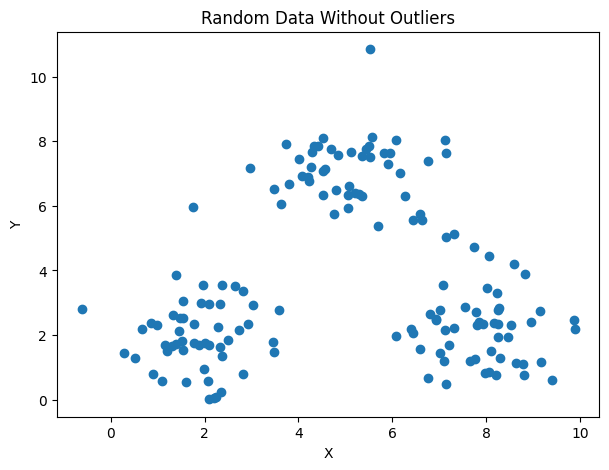

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 1])

plt.title("Random Data Without Outliers")
plt.xlabel("X")
plt.ylabel("Y")

plt.show()

In [ ]:
clusters, centroids = kmeans(X, 3)

print("Centroids:")
print(centroids)

Centroids:
[[5.04165929 7.08045085]
 [1.86432437 1.9279826 ]
 [7.87836631 2.25353365]]


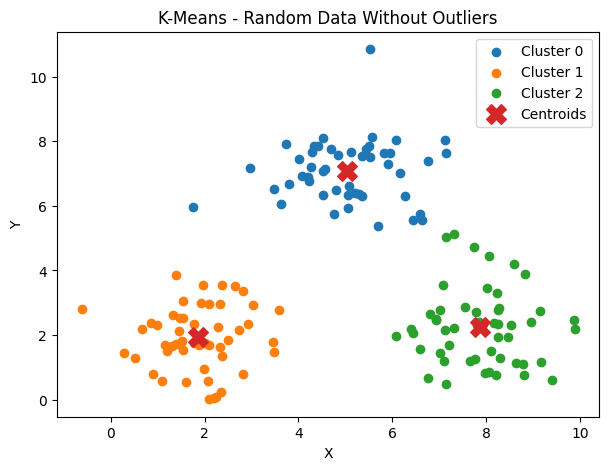

In [ ]:
plot_clusters(
    X,
    clusters,
    centroids,
    "K-Means - Random Data Without Outliers"
)

with outliers


In [ ]:
np.random.seed(42)

cluster1 = np.random.randn(50, 2) + [2, 2]
cluster2 = np.random.randn(50, 2) + [8, 2]
cluster3 = np.random.randn(50, 2) + [5, 7]

# Normal data
X_normal = np.vstack((cluster1, cluster2, cluster3))

# Outliers
outliers = np.array([
    [15, 15],
    [18, 2],
    [-5, 10],
    [20, -5],
    [-8, -5]
])

X_outlier = np.vstack((X_normal, outliers))

print("Number of data points:", len(X_outlier))

Number of data points: 155


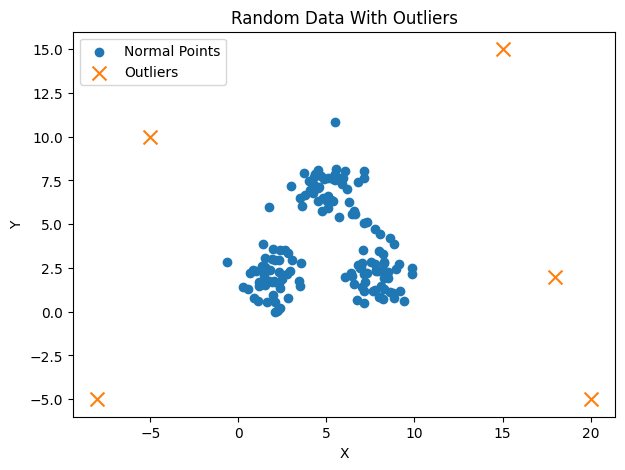

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_normal[:, 0],
    X_normal[:, 1],
    label="Normal Points"
)

plt.scatter(
    outliers[:, 0],
    outliers[:, 1],
    marker="x",
    s=100,
    label="Outliers"
)

plt.title("Random Data With Outliers")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()

plt.show()

In [ ]:
clusters, centroids = kmeans(X_outlier, 3)

print("Centroids:")
print(centroids)

Centroids:
[[5.12398726 7.21235169]
 [1.67090624 1.7921398 ]
 [8.33129531 2.00005967]]


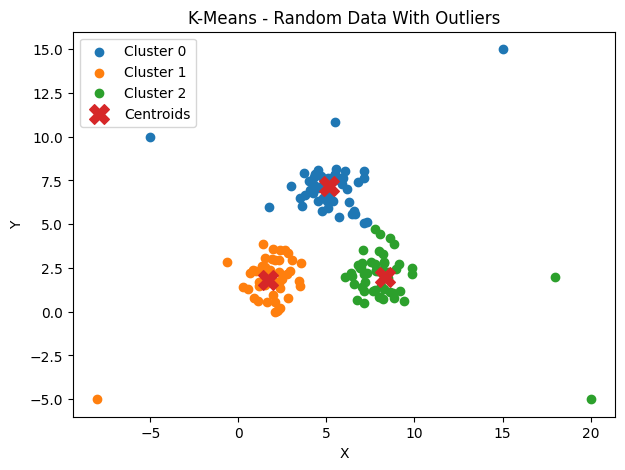

In [ ]:
plot_clusters(
    X_outlier,
    clusters,
    centroids,
    "K-Means - Random Data With Outliers"
)

In [ ]:
!pip install kagglehub

In [ ]:
import kagglehub

In [ ]:
path = kagglehub.dataset_download(
    "vjchoudhary7/customer-segmentation-tutorial-in-python"
)

print("Dataset path:", path)

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Dataset path: /kaggle/input/customer-segmentation-tutorial-in-python


In [ ]:
import os

print(os.listdir(path))

['Mall_Customers.csv']


In [ ]:
data = pd.read_csv(
    os.path.join(path, "Mall_Customers.csv")
)

data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
X_kaggle = data[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].values

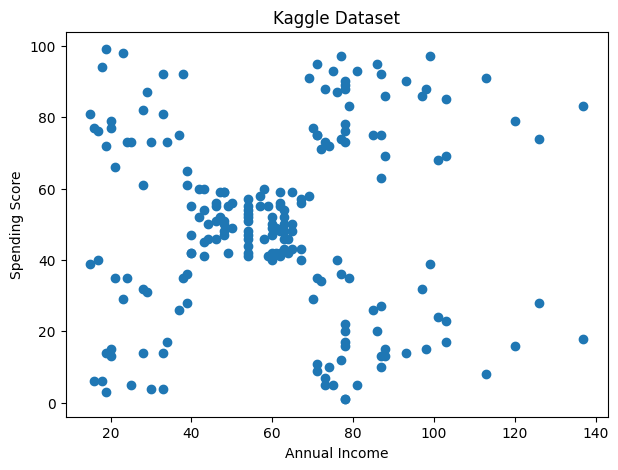

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_kaggle[:, 0],
    X_kaggle[:, 1]
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.title("Kaggle Dataset")

plt.show()

In [ ]:
clusters, centroids = kmeans(X_kaggle, 5)

print("Centroids:")
print(centroids)

Centroids:
[[55 49]
 [86 82]
 [25 20]
 [88 17]
 [25 79]]


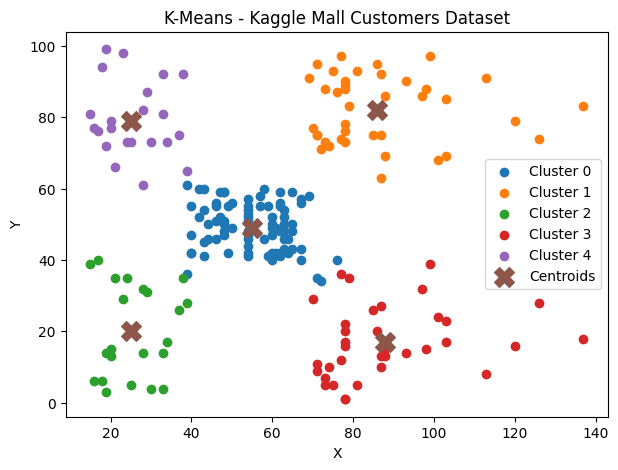

In [ ]:
plot_clusters(
    X_kaggle,
    clusters,
    centroids,
    "K-Means - Kaggle Mall Customers Dataset"
)

In [ ]:
image = Image.open("/content/Screenshot 2026-10-13 100239.png")

image = image.convert("RGB")

image_array = np.array(image)

print("Image shape:", image_array.shape)

Image shape: (437, 502, 3)


In [ ]:
height, width, channels = image_array.shape

pixels = image_array.reshape(-1, 3)

pixels = pixels.astype(float)

print("Number of pixels:", len(pixels))
print("Pixel format:", pixels.shape)

Number of pixels: 219374
Pixel format: (219374, 3)


In [ ]:
pixel_clusters, pixel_centroids = kmeans(
    pixels,
    5,
    max_iterations=20
)

print("Main colors:")
print(pixel_centroids)

Main colors:
[[248.07012266 221.5368453   87.43554405]
 [193.84150794 147.36872923  27.79213132]
 [239.73358781 239.06058113 234.76305571]
 [243.8659698  243.85481998 243.76602787]
 [254.69366326 254.69238564 254.67891916]]


In [ ]:
new_pixels = pixel_centroids[pixel_clusters]

new_pixels = new_pixels.astype(np.uint8)

new_image_array = new_pixels.reshape(
    height,
    width,
    3
)

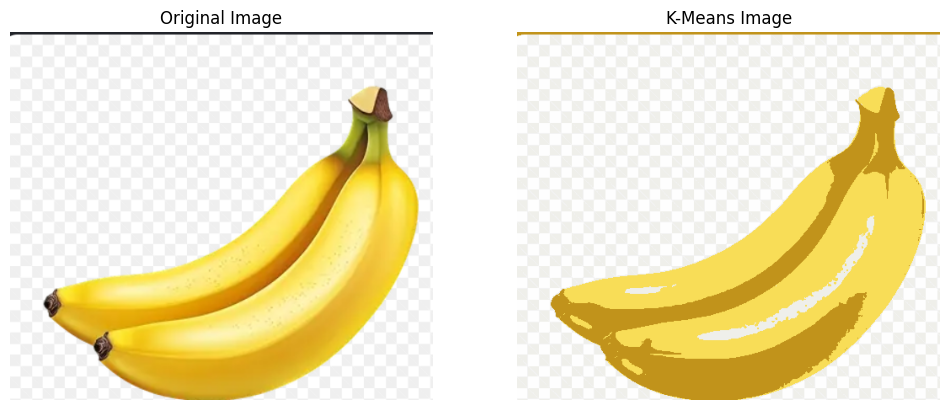

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(image_array)

plt.title("Original Image")

plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(new_image_array)

plt.title("K-Means Image")

plt.axis("off")

plt.show()

In [ ]:
def euclidean_distance(point1, point2):

    return np.sqrt(
        np.sum((point1 - point2) ** 2)
    )

In [ ]:
def cluster_distance(cluster1, cluster2, X):

    minimum_distance = float("inf")

    for i in cluster1:
        for j in cluster2:

            distance = euclidean_distance(
                X[i],
                X[j]
            )

            if distance < minimum_distance:
                minimum_distance = distance

    return minimum_distance

In [ ]:
def agglomerative_clustering(X, k):

    # Initially every point is its own cluster
    clusters = [[i] for i in range(len(X))]

    while len(clusters) > k:

        minimum_distance = float("inf")

        cluster1_index = 0
        cluster2_index = 1

        # Find two closest clusters
        for i in range(len(clusters)):

            for j in range(i + 1, len(clusters)):

                distance = cluster_distance(
                    clusters[i],
                    clusters[j],
                    X
                )

                if distance < minimum_distance:
                    minimum_distance = distance

                    cluster1_index = i
                    cluster2_index = j

        # Merge the two closest clusters
        new_cluster = (
            clusters[cluster1_index]
            + clusters[cluster2_index]
        )

        # Remove old clusters
        clusters.pop(cluster2_index)
        clusters.pop(cluster1_index)

        # Add merged cluster
        clusters.append(new_cluster)

    return clusters

In [ ]:
hierarchical_clusters = agglomerative_clustering(
    X,
    3
)

print(hierarchical_clusters)

[[104], [37, 10, 41, 17, 15, 7, 22, 3, 27, 36, 35, 1, 32, 23, 29, 33, 45, 19, 8, 13, 48, 40, 26, 4, 44, 20, 43, 12, 0, 34, 25, 38, 49, 2, 21, 5, 42, 30, 28, 14, 46, 9, 31, 47, 24, 39, 6, 18, 11, 16], [131, 118, 53, 78, 67, 61, 73, 94, 55, 65, 71, 70, 88, 96, 58, 99, 51, 84, 81, 64, 77, 69, 60, 90, 59, 82, 72, 87, 54, 93, 92, 95, 74, 75, 97, 57, 52, 86, 76, 98, 80, 79, 66, 91, 50, 68, 63, 85, 111, 124, 117, 126, 125, 123, 145, 139, 116, 147, 138, 144, 113, 132, 102, 101, 136, 130, 108, 120, 115, 109, 134, 137, 148, 106, 149, 112, 114, 119, 146, 105, 107, 143, 140, 121, 129, 100, 103, 122, 127, 62, 83, 110, 142, 56, 89, 128, 141, 133, 135]]


In [ ]:
def clusters_to_labels(clusters, n):

    labels = np.zeros(n, dtype=int)

    for cluster_number, cluster in enumerate(clusters):

        for point in cluster:
            labels[point] = cluster_number

    return labels

In [ ]:
labels = clusters_to_labels(
    hierarchical_clusters,
    len(X)
)

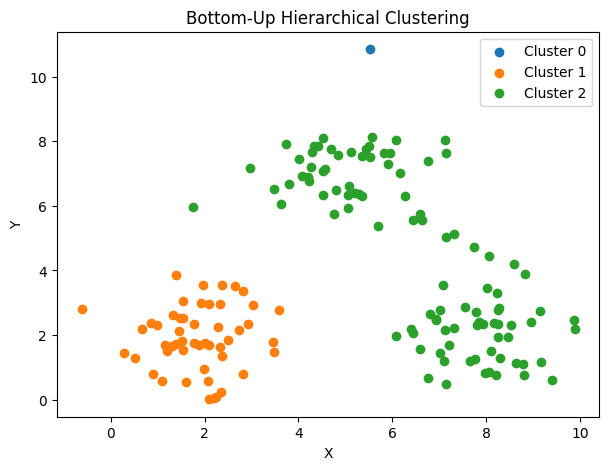

In [ ]:
plt.figure(figsize=(7, 5))

for cluster in np.unique(labels):

    points = X[labels == cluster]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        label="Cluster " + str(cluster)
    )

plt.title("Bottom-Up Hierarchical Clustering")

plt.xlabel("X")
plt.ylabel("Y")

plt.legend()

plt.show()

In [ ]:
def divisive_clustering(X, k):

    # Start with one cluster containing all points
    clusters = [list(range(len(X)))]

    while len(clusters) < k:

        # Find the largest cluster
        largest_index = 0

        for i in range(len(clusters)):

            if len(clusters[i]) > len(
                clusters[largest_index]
            ):
                largest_index = i

        # Get points from largest cluster
        selected_cluster = clusters[largest_index]

        selected_points = X[selected_cluster]

        # Split into two clusters using K-Means
        labels, centroids = kmeans(
            selected_points,
            2
        )

        cluster1 = []
        cluster2 = []

        for i in range(len(selected_cluster)):

            if labels[i] == 0:
                cluster1.append(
                    selected_cluster[i]
                )
            else:
                cluster2.append(
                    selected_cluster[i]
                )

        # Remove original cluster
        clusters.pop(largest_index)

        # Add two new clusters
        clusters.append(cluster1)
        clusters.append(cluster2)

    return clusters

In [ ]:
divisive_clusters = divisive_clustering(
    X,
    3
)

print(divisive_clusters)

[[56, 62, 89, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49], [50, 51, 52, 53, 54, 55, 57, 58, 59, 60, 61, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]]


In [ ]:
labels = clusters_to_labels(
    divisive_clusters,
    len(X)
)

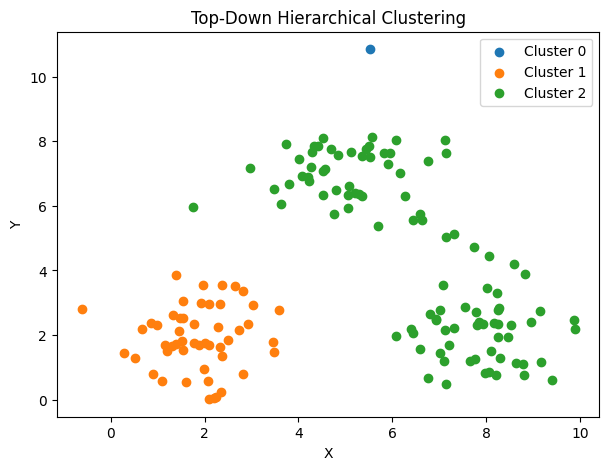

In [ ]:
plt.figure(figsize=(7, 5))

for cluster in np.unique(labels):

    points = X[labels == cluster]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        label="Cluster " + str(cluster)
    )

plt.title("Top-Down Hierarchical Clustering")

plt.xlabel("X")
plt.ylabel("Y")

plt.legend()

plt.show()

In [ ]:
clusters_bottom = agglomerative_clustering(
    X,
    3
)

labels_bottom = clusters_to_labels(
    clusters_bottom,
    len(X)
)

In [ ]:
clusters_top = divisive_clustering(
    X,
    3
)

labels_top = clusters_to_labels(
    clusters_top,
    len(X)
)

In [ ]:
clusters_bottom_outlier = agglomerative_clustering(
    X_outlier,
    3
)

labels_bottom_outlier = clusters_to_labels(
    clusters_bottom_outlier,
    len(X_outlier)
)

In [ ]:
clusters_top_outlier = divisive_clustering(
    X_outlier,
    3
)

labels_top_outlier = clusters_to_labels(
    clusters_top_outlier,
    len(X_outlier)
)

In [ ]:
clusters_bottom_kaggle = agglomerative_clustering(
    X_kaggle,
    5
)

labels_bottom_kaggle = clusters_to_labels(
    clusters_bottom_kaggle,
    len(X_kaggle)
)

In [ ]:
clusters_top_kaggle = divisive_clustering(
    X_kaggle,
    5
)

labels_top_kaggle = clusters_to_labels(
    clusters_top_kaggle,
    len(X_kaggle)
)

In [ ]:
np.random.seed(42)

sample_size = 100

sample_indices = np.random.choice(
    len(pixels),
    sample_size,
    replace=False
)

image_sample = pixels[sample_indices]

print(image_sample.shape)

(100, 3)


In [ ]:
image_bottom_clusters = agglomerative_clustering(
    image_sample,
    5
)

image_bottom_labels = clusters_to_labels(
    image_bottom_clusters,
    len(image_sample)
)

In [ ]:
image_top_clusters = divisive_clustering(
    image_sample,
    5
)

image_top_labels = clusters_to_labels(
    image_top_clusters,
    len(image_sample)
)

In [ ]:
print("K-Means")
print("--------")
print("Starts with random centroids")
print("Directly creates k clusters")
print("Fast")
print("Sensitive to outliers")


print("\nBottom-Up Hierarchical")
print("----------------------")
print("Starts with individual points")
print("Merges closest clusters")
print("Creates hierarchy")
print("Computationally expensive")


print("\nTop-Down Hierarchical")
print("---------------------")
print("Starts with one large cluster")
print("Repeatedly splits clusters")
print("Creates hierarchy")
print("Computationally expensive")

K-Means
--------
Starts with random centroids
Directly creates k clusters
Fast
Sensitive to outliers

Bottom-Up Hierarchical
----------------------
Starts with individual points
Merges closest clusters
Creates hierarchy
Computationally expensive

Top-Down Hierarchical
---------------------
Starts with one large cluster
Repeatedly splits clusters
Creates hierarchy
Computationally expensive
